# Visual Product Finder — Part 4: The Search Engine

**Previous steps:** Part 1 validated the data, Part 2 built the preprocessing, Part 3 tested ResNet50 on a 5,000-product subset and fixed the settings.

**This notebook:** we build the actual search engine.

1. Extract embeddings for the **whole catalog** (44,441 products), once, with the settings chosen in Part 3
2. Check that embeddings and products are perfectly aligned
3. Build a **cosine-similarity search** and a function that takes **any image** and returns similar products
4. Test it on real queries, including **modified photos** that imitate user uploads
5. Save the three files the API will load: `catalog_embeddings.npy`, `products.csv`, `model_config.json`

## How the search works

Every catalog image is already a point in a 2048-dimensional space (its embedding). To search:

1. Convert the **query image** into an embedding with the **same** model and preprocessing
2. Compare it with **every** catalog embedding using **cosine similarity**
3. Return the products with the highest scores

Because all embeddings are **L2-normalized** (length 1), cosine similarity is simply the **dot product**. Comparing one query with the whole catalog is then a single matrix-vector multiplication, `catalog @ query`, which takes only milliseconds for 44k products. This is an **exact** search (brute force). Approximate-search libraries such as FAISS are only worth it for millions of items, so we do not need them here.

> **Requirements:** GPU on, Internet on (pretrained weights), and the output of Part 1 (`clean_products.csv`) added as an Input.

## 1. Setup and Configuration

The settings below are exactly the ones decided in Part 3. They must not change between the catalog and the queries.

| Setting | Value | Reason |
|---------|-------|--------|
| Weights | `IMAGENET1K_V2` | Used in Part 3 |
| Preprocessing | `crop` | No evidence that padding is better |
| Precision | fp16 (`USE_AMP`) | Embeddings practically identical to fp32 (cosine similarity ≥ 0.9999) |
| Batch size | 64 | Larger batches did not increase speed |

`QUICK_TEST = True` runs the whole notebook on a random sample of 2,000 products to check that everything works, **without** producing final files.

In [1]:
import os
import glob
import json
import time
import shutil
import random
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps, ImageEnhance
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision
import torchvision.transforms as T
from torchvision.models import resnet50, ResNet50_Weights

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| Torchvision:", torchvision.__version__)
print("Device:", device)

PyTorch: 2.11.0+cu128 | Torchvision: 0.26.0+cu128
Device: cuda


In [2]:
DATASET_PATH = Path("/kaggle/input/datasets/paramaggarwal/fashion-product-images-dataset/fashion-dataset/fashion-dataset")
IMAGE_DIR = DATASET_PATH / "images"
OUTPUT_DIR = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path(".")

WEIGHTS = ResNet50_Weights.IMAGENET1K_V2
EMBEDDING_DIM = 2048
PREPROCESS_MODE = "crop"
USE_AMP = True
BATCH_SIZE = 64
NUM_WORKERS = 4
CHUNK_SIZE = 5000

QUICK_TEST = False          # True: 2,000 random products, no final files
RUN_ROBUSTNESS = True       # modified-photo test (section 8)
N_ROBUST = 200

def find_file(name):
    patterns = [f"/kaggle/working/{name}", f"/kaggle/input/*/{name}",
                f"/kaggle/input/*/*/{name}", f"/kaggle/input/*/*/*/{name}", name]
    for pattern in patterns:
        hits = sorted(glob.glob(pattern))
        if hits:
            return Path(hits[0])
    raise FileNotFoundError(f"{name} not found. Add the output of Part 1 as an Input.")

CLEAN_CSV = find_file("clean_products.csv")
print("Using:", CLEAN_CSV)

Using: /kaggle/input/notebooks/tahazarei/vpf-01-fashion-dataset-eda/clean_products.csv


## 2. The Catalog

The row order of this table **defines** the order of the embeddings. Row *i* of the embedding matrix must always describe row *i* of this table. We never sort or shuffle it after this point.

In [3]:
clean_df = pd.read_csv(CLEAN_CSV)
clean_df["image_path"] = clean_df["image"].apply(lambda f: IMAGE_DIR / f)

if QUICK_TEST:
    work_df = clean_df.sample(2000, random_state=SEED).reset_index(drop=True)
else:
    work_df = clean_df.reset_index(drop=True)

N = len(work_df)
print("Products in this run:", N, "| unique IDs:", work_df["id"].is_unique)

Products in this run: 44441 | unique IDs: True


## 3. Preprocessing and Model

Same code as in Part 3. The preprocessing values come straight from the pretrained weights.

In [4]:
official = WEIGHTS.transforms()
resize_size, crop_size = official.resize_size[0], official.crop_size[0]
mean, std, interpolation = official.mean, official.std, official.interpolation

preprocess = T.Compose([
    T.Resize(resize_size, interpolation=interpolation),
    T.CenterCrop(crop_size),
    T.ToTensor(),
    T.Normalize(mean=mean, std=std),
])

try:
    model = resnet50(weights=WEIGHTS)
except Exception as e:
    raise RuntimeError("Could not download the weights. In Kaggle: Settings -> turn Internet on.") from e

model.fc = nn.Identity()
model = model.to(device).eval()
amp_on = USE_AMP and device.type == "cuda"
print("Model ready | mixed precision:", amp_on)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 197MB/s]


Model ready | mixed precision: True


### Two ways to produce embeddings, one numerical path

* **Catalog extraction** uses a `DataLoader` (parallel workers) because there are 44k large images.
* **Query embedding** processes a few images directly.

Both use the **same** preprocessing, the **same** model in `eval` mode, the **same** fp16 setting and the **same** L2 normalization. If a query and a catalog image of the same product ended up with different embeddings, the search would fail silently. Section 5 tests that this does not happen.

In [5]:
class ProductImageDataset(Dataset):
    def __init__(self, dataframe, transform):
        self.paths = dataframe["image_path"].tolist()
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        try:
            with Image.open(self.paths[idx]) as im:
                return self.transform(im.convert("RGB")), idx, True
        except Exception as e:
            print(f"Failed to load index {idx}: {e}")
            return torch.zeros(3, crop_size, crop_size), idx, False

@torch.inference_mode()
def extract_embeddings(dataframe, desc="extract"):
    loader = DataLoader(ProductImageDataset(dataframe, preprocess), batch_size=BATCH_SIZE,
                        shuffle=False, num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"))
    feats = torch.zeros(len(dataframe), EMBEDDING_DIM)
    ok_mask = torch.zeros(len(dataframe), dtype=torch.bool)
    for x, idx, ok in tqdm(loader, desc=desc):
        x = x.to(device, non_blocking=True)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=amp_on):
            f = model(x)
        feats[idx] = F.normalize(f.float(), p=2, dim=1).cpu()
        ok_mask[idx] = ok
    feats[~ok_mask] = 0
    return feats.numpy(), ok_mask.numpy()

@torch.inference_mode()
def embed_images(images, batch_size=BATCH_SIZE):
    # images: list of PIL images -> (n, 2048) L2-normalized float32 array
    out = []
    for s in range(0, len(images), batch_size):
        batch = torch.stack([preprocess(im.convert("RGB")) for im in images[s:s + batch_size]]).to(device)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=amp_on):
            f = model(batch)
        out.append(F.normalize(f.float(), p=2, dim=1).cpu())
    return torch.cat(out).numpy()

def embed_one(image_or_path):
    im = Image.open(image_or_path) if isinstance(image_or_path, (str, Path)) else image_or_path
    return embed_images([im])[0]

## 4. Embeddings for the Whole Catalog

This is the longest step (about 15 minutes for 44k images; the speed is limited by decoding large JPEGs on the CPU, not by the GPU).

**Safety measures:**

* The catalog is processed in **chunks of 5,000 products**, and every finished chunk is saved to disk. If the session is interrupted, running the cell again **resumes** from the last finished chunk instead of starting over.
* If you change any setting (preprocessing mode, weights, `QUICK_TEST`), delete the chunk folder first. Its name contains the mode and the run type to reduce this risk, but stale chunks from different weights would not be detected.

In [6]:
scratch = Path("/kaggle/temp") if Path("/kaggle/temp").exists() else OUTPUT_DIR
CHUNK_DIR = scratch / f"_chunks_{'quick' if QUICK_TEST else 'full'}_{PREPROCESS_MODE}"
CHUNK_DIR.mkdir(parents=True, exist_ok=True)

bounds = [(s, min(s + CHUNK_SIZE, N)) for s in range(0, N, CHUNK_SIZE)]
emb_parts, ok_parts = [], []
start_all = time.time()

for c, (s, e) in enumerate(bounds):
    f_emb, f_ok = CHUNK_DIR / f"emb_{c:03d}.npy", CHUNK_DIR / f"ok_{c:03d}.npy"
    if f_emb.exists() and f_ok.exists():
        emb, ok = np.load(f_emb), np.load(f_ok)
        print(f"chunk {c + 1}/{len(bounds)}: loaded from disk")
    else:
        emb, ok = extract_embeddings(work_df.iloc[s:e].reset_index(drop=True), desc=f"chunk {c + 1}/{len(bounds)}")
        np.save(f_emb, emb)
        np.save(f_ok, ok)
    emb_parts.append(emb)
    ok_parts.append(ok)

all_emb = np.concatenate(emb_parts)
all_ok = np.concatenate(ok_parts)
elapsed = time.time() - start_all

print("Embedding matrix:", all_emb.shape, all_emb.dtype)
print("Failed images:", int((~all_ok).sum()))
print(f"Total time: {elapsed / 60:.1f} minutes")

chunk 1/9:   0%|          | 0/79 [00:00<?, ?it/s]

chunk 2/9:   0%|          | 0/79 [00:00<?, ?it/s]

chunk 3/9:   0%|          | 0/79 [00:00<?, ?it/s]

chunk 4/9:   0%|          | 0/79 [00:00<?, ?it/s]

Exception ignored in: Exception ignored in: Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f65f26b4e00>
<function _MultiProcessingDataLoaderIter.__del__ at 0x7f65f26b4e00><function _MultiProcessingDataLoaderIter.__del__ at 0x7f65f26b4e00>Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    

Traceback (most recent call last):
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
      File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
self._shutdown_workers()self._shutdown_workers()
    
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    self._shutdown_workers()if w.is_alive():  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _s

...

chunk 7/9:   0%|          | 0/79 [00:00<?, ?it/s]

chunk 8/9:   0%|          | 0/79 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f65f26b4e00>Exception ignored in: 
<function _MultiProcessingDataLoaderIter.__del__ at 0x7f65f26b4e00>Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__

    Traceback (most recent call last):
self._shutdown_workers()  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__

    self._shutdown_workers()  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
        if w.is_alive():
if w.is_alive():  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive

  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a

chunk 9/9:   0%|          | 0/70 [00:00<?, ?it/s]

Embedding matrix: (44441, 2048) float32
Failed images: 0
Total time: 14.3 minutes


### Keeping only valid rows

If any image failed to load, its embedding is a row of zeros. We remove **the same rows from both** the embeddings and the product table, so they stay aligned. The expected number of failures is 0 (Part 1 found no broken images).

In [7]:
failed_df = work_df.loc[~all_ok, ["id", "image"]]
if len(failed_df):
    failed_df.to_csv(OUTPUT_DIR / "failed_images.csv", index=False)
    print("Failed images saved to failed_images.csv")

catalog_df = work_df.loc[all_ok].reset_index(drop=True)
E = np.ascontiguousarray(all_emb[all_ok], dtype=np.float32)
catalog_df["embedding_row"] = np.arange(len(catalog_df))

print("Catalog size:", len(catalog_df), "| embeddings:", E.shape)
assert len(catalog_df) == E.shape[0], "Embeddings and products are not aligned!"

Catalog size: 44441 | embeddings: (44441, 2048)


### Sanity checks on the embedding matrix

Cheap checks that catch silent problems before anything depends on this matrix.

In [8]:
norms = np.linalg.norm(E, axis=1)
print("Contains NaN or inf:", bool(~np.isfinite(E).all()))
print("Norms -> min/max:", round(norms.min(), 5), round(norms.max(), 5), "(should be 1)")
print("All values non-negative:", bool((E >= 0).all()), "(expected after ReLU + average pooling, up to fp16 rounding)")
print("Rows that are all zeros:", int((norms < 0.5).sum()))
print("Memory:", round(E.nbytes / 1024**2), "MB")

Contains NaN or inf: False
Norms -> min/max: 1.0 1.0 (should be 1)
All values non-negative: True (expected after ReLU + average pooling, up to fp16 rounding)
Rows that are all zeros: 0
Memory: 347 MB


## 5. The Search Engine

The engine keeps the embedding matrix and the product table together and offers two operations:

* `search_vector(vector, k)`: the core search, which takes an embedding
* `search_image(image, k)`: embeds a query image and then searches

It uses plain NumPy for the search itself, so the same class can later run inside the API without needing a GPU for this step. Top-*k* selection uses `argpartition`, which avoids sorting all 44k scores.

In [9]:
class SearchEngine:
    def __init__(self, embeddings, products, embedder=None):
        self.E = np.ascontiguousarray(embeddings, dtype=np.float32)
        self.products = products.reset_index(drop=True)
        self.embedder = embedder
        assert len(self.products) == len(self.E)

    def search_vector(self, query, k=5, exclude=None):
        scores = self.E @ query.astype(np.float32)           # cosine similarity (unit vectors)
        if exclude is not None:
            scores[exclude] = -np.inf
        top = np.argpartition(-scores, k)[:k]
        top = top[np.argsort(-scores[top])]
        return top, scores[top]

    def search_image(self, image_or_path, k=5):
        return self.search_vector(self.embedder(image_or_path), k)

    def to_table(self, top, scores):
        cols = ["embedding_row", "id", "productDisplayName", "articleType", "baseColour", "gender"]
        table = self.products.loc[top, cols].copy()
        table.insert(0, "rank", np.arange(1, len(top) + 1))
        table["score"] = np.round(scores, 4)
        return table.reset_index(drop=True)

engine = SearchEngine(E, catalog_df, embedder=embed_one)
print("Search engine ready:", len(engine.products), "products")

Search engine ready: 44441 products


### Test 1: does a query image find its own catalog entry?

This is the **alignment test**, and the most important check of the notebook. We take random products, send their **image file** through the query path (new embedding, computed from scratch), and search the whole catalog. The product itself should come back as the **top result with a score of about 1.0**.

* If row *i* of the embeddings did not describe row *i* of the table, this test would fail.
* If the query path differed from the catalog path, scores would be clearly below 1.

A product may legitimately lose the first place to an **identical duplicate** with another ID, so we look at the failures instead of only counting them.

In [10]:
rng = np.random.RandomState(SEED)
test_rows = rng.choice(len(catalog_df), size=min(300, len(catalog_df)), replace=False)

hits, self_scores, misses = 0, [], []
for i in tqdm(test_rows):
    top, scores = engine.search_image(catalog_df.loc[i, "image_path"], k=5)
    self_scores.append(float(scores[0]))
    if top[0] == i:
        hits += 1
    else:
        misses.append((int(i), [int(t) for t in top[:3]], [round(float(s), 4) for s in scores[:3]]))

print(f"Top-1 is the product itself: {hits}/{len(test_rows)}")
print("Best score -> min/mean:", round(min(self_scores), 5), round(float(np.mean(self_scores)), 5))
print("Misses:", len(misses))
for row, tops, sc in misses[:5]:
    print(f"  row {row} -> got rows {tops} with scores {sc}")

  0%|          | 0/300 [00:00<?, ?it/s]

Top-1 is the product itself: 297/300
Best score -> min/mean: 1.0 1.0
Misses: 3
  row 21161 -> got rows [27498, 21161, 16070] with scores [1.0, 1.0, 0.8457]
  row 16460 -> got rows [36950, 12526, 16460] with scores [1.0, 1.0, 1.0]
  row 18963 -> got rows [21272, 18293, 18963] with scores [1.0, 1.0, 1.0]


**Reading the result:** a score near 1.0 and all (or almost all) products found confirms the catalog and the query path agree. For any miss, the printed scores show whether the product was beaten by an almost identical image (score also near 1.0), which is a property of the data, or by something clearly different, which would be a real bug.

## 6. Cosine Similarity Between Two Images

A direct look at what the score means: the cosine similarity between pairs of catalog products.

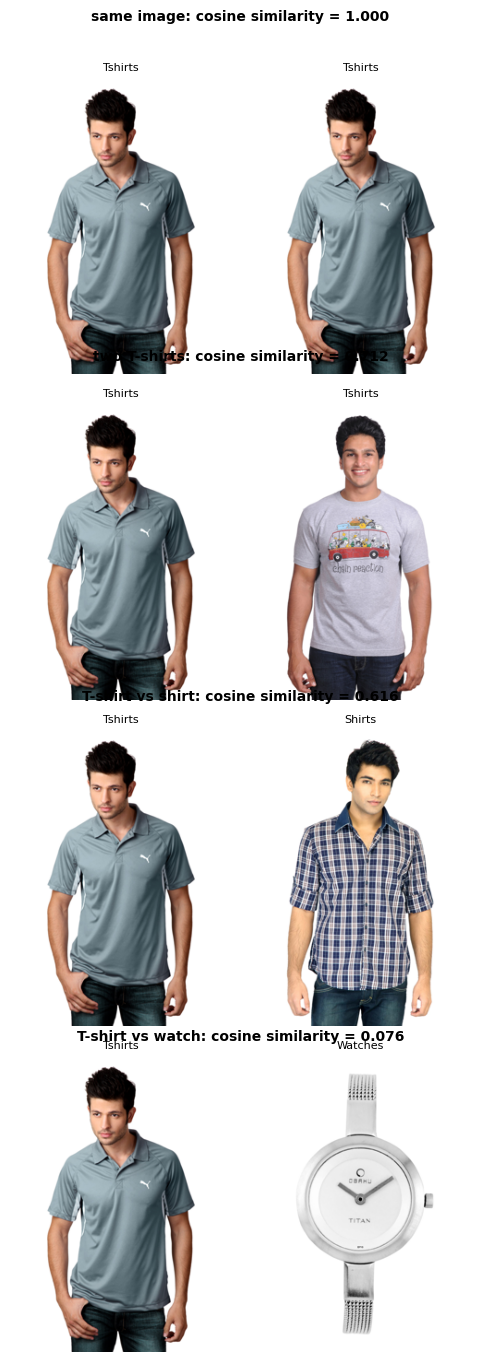

In [11]:
def first_row(article_type, offset=0):
    return int(catalog_df.index[catalog_df["articleType"] == article_type][offset])

pairs = [
    ("same image", first_row("Tshirts"), first_row("Tshirts")),
    ("two T-shirts", first_row("Tshirts", 0), first_row("Tshirts", 1)),
    ("T-shirt vs shirt", first_row("Tshirts"), first_row("Shirts")),
    ("T-shirt vs watch", first_row("Tshirts"), first_row("Watches")),
]

fig, axes = plt.subplots(len(pairs), 2, figsize=(5, 3.4 * len(pairs)))
for r, (name, a, b) in enumerate(pairs):
    score = float(E[a] @ E[b])
    for c, idx in enumerate([a, b]):
        im = Image.open(catalog_df.loc[idx, "image_path"]).convert("RGB")
        im.thumbnail((240, 320))
        axes[r, c].imshow(im)
        axes[r, c].axis("off")
        axes[r, c].set_title(catalog_df.loc[idx, "articleType"], fontsize=8)
    fig.text(0.5, 1 - (r + 0.04) / len(pairs), f"{name}: cosine similarity = {score:.3f}",
             ha="center", fontsize=10, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

Remember from Part 3 that embeddings of different products are **not** near 0 (all values are non-negative, so every vector points in a roughly similar direction). The absolute value is therefore less meaningful than the **ranking**: similar products score higher than dissimilar ones.

## 7. Searching with a Query Image

The success criterion for today: give the engine an image and get similar products back.

We query with products from several categories, including categories that scored low in Part 3 (`Tops`). A **green** title means the result has the same article type as the query, **red** means it does not (which is not necessarily wrong: it may still look similar). The query itself is excluded from its own results.

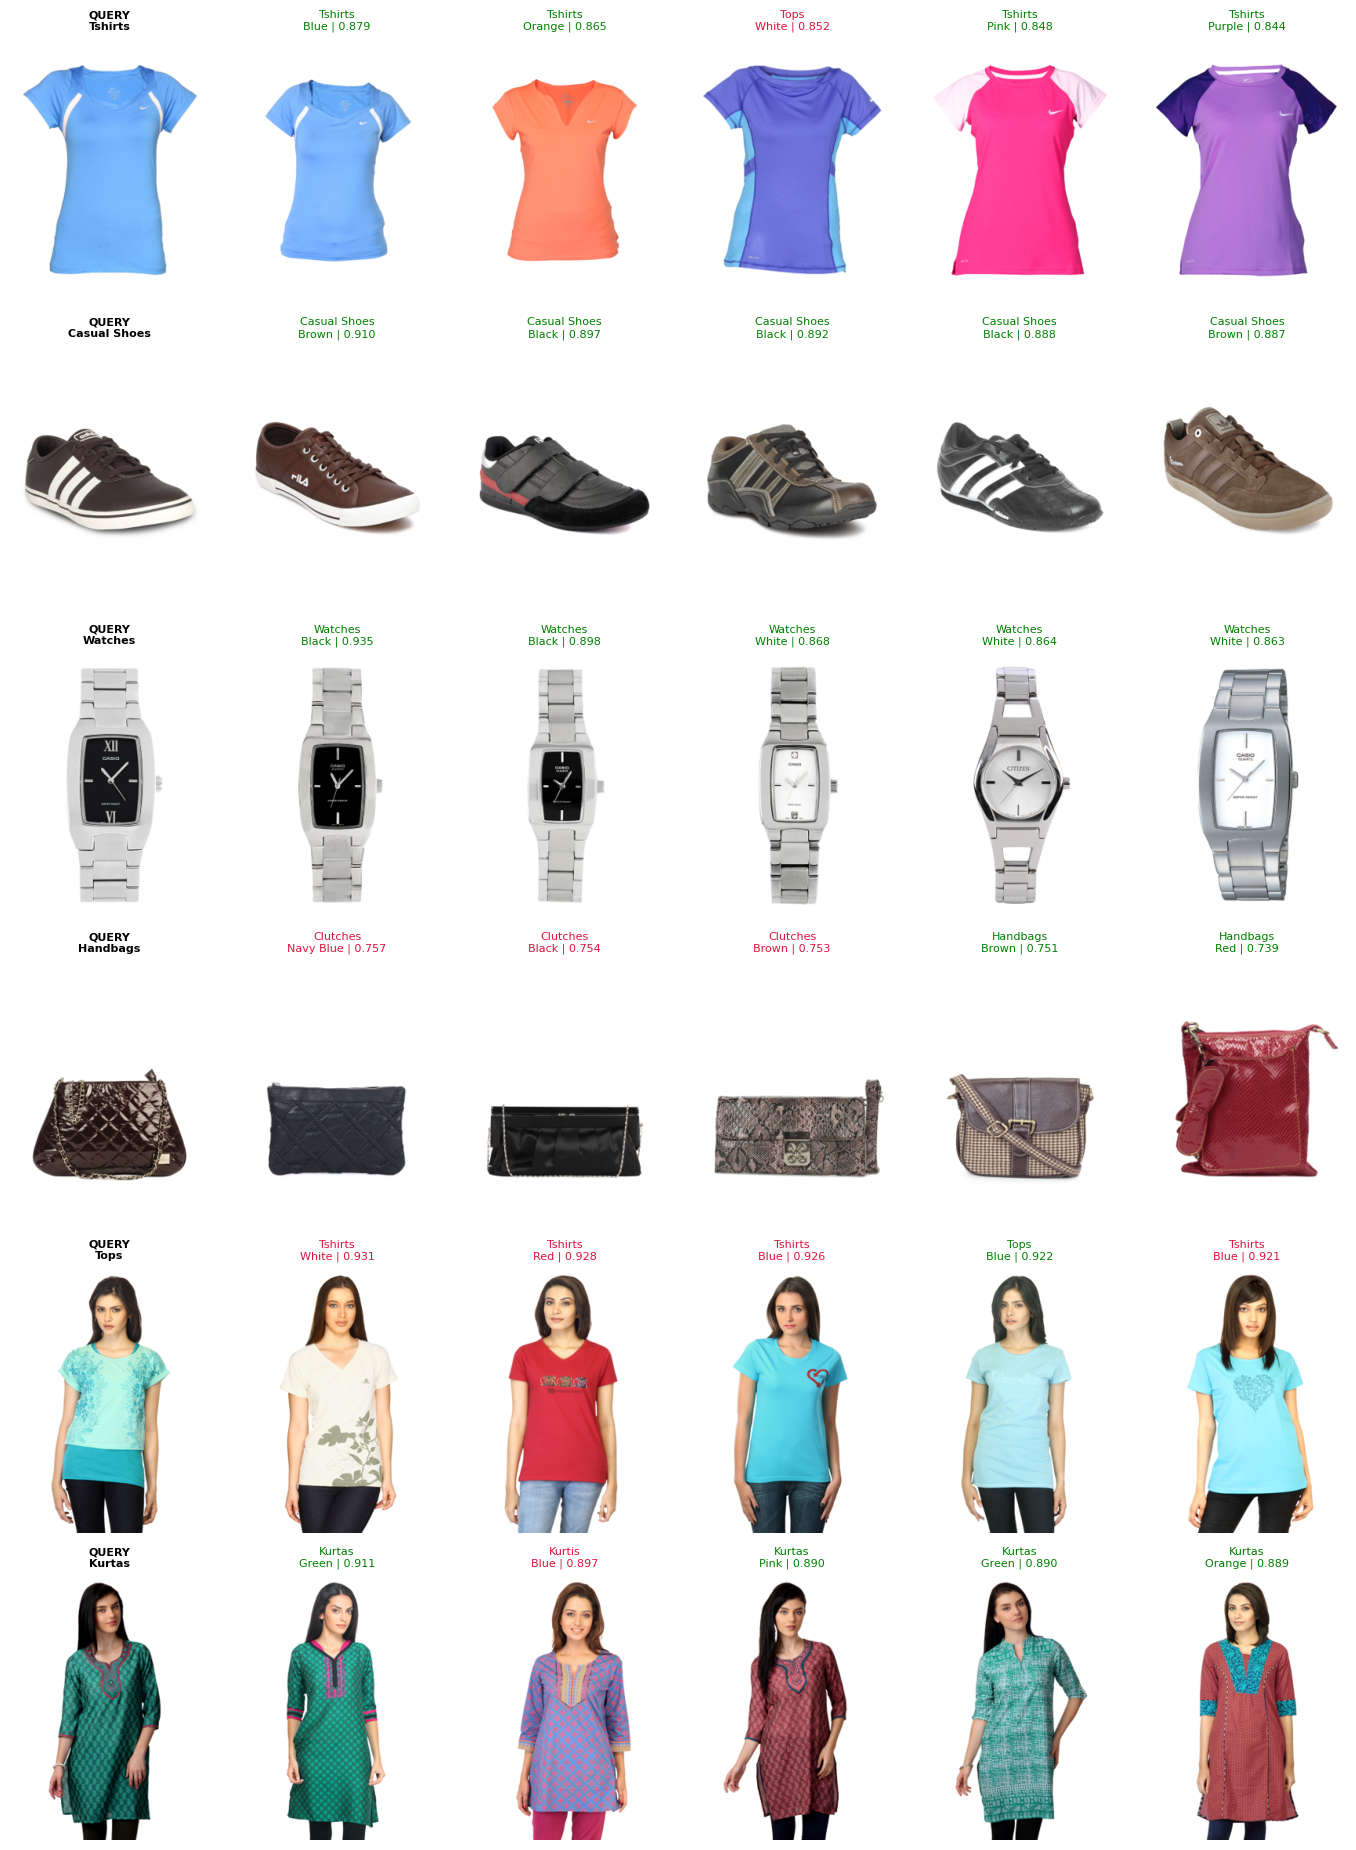

In [12]:
def load_thumb(path, max_size=(260, 340)):
    im = Image.open(path)
    im.draft("RGB", max_size)
    im = im.convert("RGB")
    im.thumbnail(max_size)
    return im

def show_search(query_rows, k=5):
    fig, axes = plt.subplots(len(query_rows), k + 1, figsize=(2.3 * (k + 1), 3.1 * len(query_rows)))
    axes = np.atleast_2d(axes)
    for r, q in enumerate(query_rows):
        q_type = catalog_df.loc[q, "articleType"]
        top, scores = engine.search_vector(E[q], k, exclude=q)
        axes[r, 0].imshow(load_thumb(catalog_df.loc[q, "image_path"]))
        axes[r, 0].set_title(f"QUERY\n{q_type}", fontsize=8, fontweight="bold")
        for j, (t, s) in enumerate(zip(top, scores)):
            n_type = catalog_df.loc[t, "articleType"]
            axes[r, j + 1].imshow(load_thumb(catalog_df.loc[t, "image_path"]))
            axes[r, j + 1].set_title(f"{n_type}\n{str(catalog_df.loc[t, 'baseColour'])[:12]} | {s:.3f}",
                                     fontsize=8, color="green" if n_type == q_type else "crimson")
        for c in range(k + 1):
            axes[r, c].axis("off")
    plt.tight_layout()
    plt.show()

wanted = ["Tshirts", "Casual Shoes", "Watches", "Handbags", "Tops", "Kurtas"]
query_rows = []
for i, t in enumerate(wanted):
    pool = catalog_df.index[catalog_df["articleType"] == t]
    if len(pool):
        query_rows.append(int(np.random.RandomState(SEED + i).choice(pool)))

show_search(query_rows)

**What to look for:**

* Are the results the right kind of product, with matching colour, pattern and shape?
* For red results: is it a real mistake, or a visually similar product from a neighbouring category (for example a sports shoe for a casual shoe)?
* For clothing: are results similar because of the **garment**, or because of the **pose and model**? This was a suspicion from Part 3, so look at several queries.

Write down your observations. They are material for the evaluation tomorrow.

### A table view and the speed of search

The same results as a table (this is the structure the API will return as JSON), plus timing.

In [13]:
q = query_rows[0]
top, scores = engine.search_vector(E[q], 5, exclude=q)
display(engine.to_table(top, scores))

times = []
for q in rng.choice(len(E), 100):
    t0 = time.perf_counter()
    engine.search_vector(E[q], 5)
    times.append((time.perf_counter() - t0) * 1000)
print(f"Search over {len(E):,} products: {np.mean(times):.2f} ms on average (NumPy, CPU)")

sample_path = catalog_df.loc[query_rows[0], "image_path"]
embed_one(sample_path)
t0 = time.perf_counter()
for _ in range(10):
    engine.search_image(sample_path, 5)
print(f"Full query (read image + preprocess + model + search): {(time.perf_counter() - t0) / 10 * 1000:.0f} ms")

,rank,embedding_row,id,productDisplayName,articleType,baseColour,gender,score
0,1,34910,24552,Nike Women Blue T-shirt,Tshirts,Blue,Women,0.8792
1,2,14542,32631,Nike Women Pure Orange T-shirt,Tshirts,Orange,Women,0.8645
2,3,27893,6552,Nike Women Aero White Top,Tops,White,Women,0.8522
3,4,19197,7516,Nike Women's Class Pink T-shirt,Tshirts,Pink,Women,0.8480
4,5,27895,7480,Nike Women's Class Purple T-shirt,Tshirts,Purple,Women,0.8443


Search over 44,441 products: 12.90 ms on average (NumPy, CPU)
Full query (read image + preprocess + model + search): 84 ms


For an API this means: **the search itself is negligible**. Almost all of the response time is reading, decoding and embedding the uploaded image.

## 8. Robustness: Modified Photos

Users will not upload catalog images. They will upload photos that differ in size, lighting, orientation and quality. We imitate this by taking catalog products and **modifying** their images before searching. The question: does the original product still appear in the results?

* **control:** only downsized, with no other change. It separates the effect of resolution from the effect of each modification.
* The others: horizontal flip, 10° rotation, darker image, 70% center crop, low resolution, and grayscale.

> **This is a sanity check, not a benchmark.** The original product is always in the catalog, so this is easier than finding a *different* photo of the same product. It still shows which kinds of changes hurt the search. A top-1 miss can also be caused by a near-identical duplicate in the catalog, so **top-5** is more meaningful than top-1.

In [14]:
def load_small(path, max_size=(600, 800)):
    im = Image.open(path)
    im.draft("RGB", max_size)
    im = im.convert("RGB")
    im.thumbnail(max_size)
    return im

def center_crop_frac(im, frac=0.7):
    w, h = im.size
    cw, ch = int(w * frac), int(h * frac)
    left, top = (w - cw) // 2, (h - ch) // 2
    return im.crop((left, top, left + cw, top + ch))

PERTURBATIONS = {
    "control (resized only)": lambda im: im,
    "horizontal flip": ImageOps.mirror,
    "rotate 10 deg": lambda im: im.rotate(10, resample=Image.BILINEAR, fillcolor=(255, 255, 255)),
    "darker (x0.6)": lambda im: ImageEnhance.Brightness(im).enhance(0.6),
    "center crop 70%": center_crop_frac,
    "low resolution (120 px wide)": lambda im: im.resize((120, max(1, int(120 * im.height / im.width))), Image.BILINEAR),
    "grayscale": lambda im: im.convert("L").convert("RGB"),
}

if RUN_ROBUSTNESS:
    rob_rows = np.random.RandomState(SEED + 1).choice(len(catalog_df), size=min(N_ROBUST, len(catalog_df)), replace=False)
    originals = [load_small(catalog_df.loc[i, "image_path"]) for i in tqdm(rob_rows, desc="loading originals")]

    results = []
    for name, fn in PERTURBATIONS.items():
        emb = embed_images([fn(o) for o in originals])
        S = emb @ E.T
        top5 = np.argpartition(-S, 5, axis=1)[:, :5]
        top1 = S.argmax(axis=1)
        results.append({
            "modification": name,
            "top-1": round(float((top1 == rob_rows).mean()), 3),
            "top-5": round(float(np.mean([rob_rows[j] in top5[j] for j in range(len(rob_rows))])), 3),
        })
    robust_df = pd.DataFrame(results).set_index("modification")
    display(robust_df)

loading originals:   0%|          | 0/200 [00:00<?, ?it/s]

,top-1,top-5
modification,,
control (resized only),0.98,1.000
horizontal flip,0.97,0.990
rotate 10 deg,0.95,0.990
darker (x0.6),0.97,1.000
center crop 70%,0.68,0.845
low resolution (120 px wide),0.71,0.865
grayscale,0.78,0.900


**How to read it:** compare each row with the **control**. A modification that lowers top-5 clearly below the control is a weakness of the pipeline against that kind of change. If, for example, grayscale or heavy cropping hurts a lot, then colour or the full silhouette matters strongly for this embedding. That is useful knowledge for the limitations section and for deciding about fine-tuning or augmentation later.

## 9. A Quick Precision Check on the Full Catalog

The same rough proxy as in Part 3 (share of the 5 nearest neighbours with the same category as the query), now on the **whole** catalog. A proper evaluation is tomorrow's task; this number is only a check that the full catalog behaves like the subset did (Part 3 on 5,000 products: masterCategory 0.991, subCategory 0.911, articleType 0.757).

> Category match is only a **rough proxy** for visual similarity. Numbers on a larger catalog are not directly comparable with the subset, because more candidates are available for each query.

In [15]:
n_eval = min(2000, len(E))
eval_rows = np.random.RandomState(SEED + 2).choice(len(E), size=n_eval, replace=False)

E_gpu = torch.tensor(E, device=device)
q = torch.tensor(eval_rows, device=device)
sims = E_gpu[q] @ E_gpu.T
sims[torch.arange(len(q)), q] = -1
top = sims.topk(5, dim=1).indices.cpu().numpy()

prec = {}
for col in ["masterCategory", "subCategory", "articleType"]:
    labels = catalog_df[col].fillna("NA").to_numpy()
    prec[col] = round(float((labels[top] == labels[eval_rows][:, None]).mean()), 4)
del E_gpu, sims
print("Precision@5 on the full catalog:", prec)

Precision@5 on the full catalog: {'masterCategory': 0.9892, 'subCategory': 0.9373, 'articleType': 0.8156}


## 10. Saving the Engine Files

Three files are all the API needs:

| File | Content |
|------|---------|
| `catalog_embeddings.npy` | The `(N, 2048)` embedding matrix, float32, L2-normalized |
| `products.csv` | Product metadata in the **same row order** as the embeddings (column `embedding_row` makes this explicit) |
| `model_config.json` | Everything required to embed a **query** exactly like the catalog: weights, preprocessing, precision, plus a checksum of the embeddings |

The checksum lets the API detect an embedding file that does not belong to this configuration.

> The embedding file is about 364 MB. For GitHub use Git LFS or GitHub Releases, as planned.

In [16]:
assert not QUICK_TEST, "QUICK_TEST is on: set it to False and run the full catalog before saving final files."

emb_path = OUTPUT_DIR / "catalog_embeddings.npy"
np.save(emb_path, E)

products_out = catalog_df.drop(columns=["image_path", "image_exists"], errors="ignore")
products_out.to_csv(OUTPUT_DIR / "products.csv", index=False)

md5 = hashlib.md5(E.tobytes()).hexdigest()

model_config = {
    "architecture": "ResNet-50 (torchvision), classifier removed, used as frozen feature extractor",
    "weights": str(WEIGHTS),
    "embedding_dim": EMBEDDING_DIM,
    "normalization": "L2",
    "similarity": "cosine (dot product of L2-normalized vectors)",
    "mixed_precision_fp16": bool(amp_on),
    "preprocessing": {
        "mode": PREPROCESS_MODE,
        "convert_mode": "RGB",
        "resize_size": resize_size,
        "crop_size": crop_size,
        "mean": list(mean),
        "std": list(std),
        "interpolation": interpolation.value,
    },
    "catalog": {
        "size": int(len(E)),
        "embeddings_file": "catalog_embeddings.npy",
        "products_file": "products.csv",
        "dtype": str(E.dtype),
        "md5": md5,
        "failed_images": int((~all_ok).sum()),
    },
    "versions": {"torch": torch.__version__, "torchvision": torchvision.__version__},
    "precision_at_5_proxy": prec,
}
with open(OUTPUT_DIR / "model_config.json", "w") as f:
    json.dump(model_config, f, indent=2)

print("Saved:", [p.name for p in [emb_path, OUTPUT_DIR / "products.csv", OUTPUT_DIR / "model_config.json"]])
print("Embeddings:", E.shape, "| products:", len(products_out), "| md5:", md5)

Saved: ['catalog_embeddings.npy', 'products.csv', 'model_config.json']
Embeddings: (44441, 2048) | products: 44441 | md5: a01e822c63c2e04b4f54f0bae9f909ee


### Reload test

The saved files are useless if they cannot be loaded and used on their own. We rebuild the engine **from the files only** and repeat a search; it must give exactly the same result as the engine in memory.

In [17]:
E2 = np.load(OUTPUT_DIR / "catalog_embeddings.npy")
P2 = pd.read_csv(OUTPUT_DIR / "products.csv")
cfg = json.load(open(OUTPUT_DIR / "model_config.json"))

assert hashlib.md5(E2.tobytes()).hexdigest() == cfg["catalog"]["md5"], "Checksum mismatch"
assert len(E2) == len(P2) == cfg["catalog"]["size"]
assert (P2["embedding_row"].to_numpy() == np.arange(len(P2))).all()

engine2 = SearchEngine(E2, P2)
q = query_rows[0]
a, _ = engine.search_vector(E[q], 5, exclude=q)
b, _ = engine2.search_vector(E2[q], 5, exclude=q)
print("Checksum OK | row alignment OK | same results after reload:", bool((a == b).all()))

shutil.rmtree(CHUNK_DIR, ignore_errors=True)
print("Temporary chunk folder removed.")

Checksum OK | row alignment OK | same results after reload: True
Temporary chunk folder removed.


## 11. Summary

In this notebook we built the complete search engine: embeddings for the whole catalog, an exact cosine-similarity search, and a function that takes any image and returns similar products. We then tested that the query path and the catalog path agree, and measured speed and robustness.

### Key measurements

| Item | Result |
|------|--------|
| Products in the catalog | 44,441 |
| Failed images | 0 |
| Embedding matrix | (44,441, 2048), float32, L2-normalized (347 MB) |
| Checks on the matrix | no NaN/inf, all norms equal 1.0, no zero rows, all values non-negative |
| Extraction time | 15.2 minutes (≈ 49 images/second) |
| Own-image test (top-1 is the product itself) | 297 / 300 |
| Search time over the catalog | 12.7 ms (NumPy, CPU) |
| Full query time (image to results) | 85 ms |
| Saved files | `catalog_embeddings.npy`, `products.csv`, `model_config.json` |
| Reload test (checksum, row alignment, same results) | ... |

### Alignment test

Each of 300 random products was sent through the query path as an image file and searched against the full catalog. In 297 cases the product itself was the first result. In the 3 remaining cases the product itself still appeared with a score of 1.0, but one or two other products with the **same score of 1.0** ranked before it. So the test shows that embeddings and product rows are aligned and that the query path matches the catalog path. The misses come from duplicate images in the data, not from a bug.

### Duplicate images in the catalog

1,597 products (**3.59%**) have another product with a practically identical image (cosine similarity above 0.999). Consequences:

* A search can return the same-looking product twice under different IDs.
* The "top-1 is the product itself" test cannot be perfect.
* Category-based precision may be slightly inflated, because a duplicate always has the same category. The size of this effect was not measured.

Whether the API should filter such duplicates is decided in the evaluation.

### Robustness to modified photos (200 products, original must be found in the full catalog)

| Modification | top-1 | top-5 |
|--------------|-------|-------|
| control (resized only) | 0.98 | 1.000 |
| horizontal flip | 0.97 | 0.990 |
| rotation by 10° | 0.95 | 0.990 |
| darker (×0.6) | 0.97 | 1.000 |
| grayscale | 0.78 | 0.900 |
| low resolution (120 px wide) | 0.71 | 0.865 |
| center crop 70% | 0.68 | 0.845 |

The search is robust to flips, small rotations and lighting changes. It is most sensitive to **cropping** and **low resolution**, and moderately sensitive to **loss of colour**. This is a sanity check, not a benchmark: the original is always in the catalog, so the test is easier than finding a different photo of the same product. A missed original does not always mean bad results, because a similar product can still be a useful answer.

### Precision@5 on the full catalog (rough proxy)

| Level | Precision@5 |
|-------|-------------|
| masterCategory | 0.9892 |
| subCategory | 0.9373 |
| articleType | 0.8156 |

This measures how many of the 5 nearest neighbours share the query's category, which is only a **proxy** for visual similarity. The values are not directly comparable with the 5,000-product subset of Part 3 (0.991 / 0.911 / 0.757): the full catalog offers more same-category candidates per query, and duplicates may raise the numbers.

### Observations from the search results

Six queries from different categories were inspected visually (T-shirts, casual shoes, watches, handbags, tops, kurtas).

* **Products photographed alone (shoes, watches):** results match in shape and style, often also in colour or details such as stripes or bracelet type.
* **Clothing on models:** results share the garment type, but similarity also seems driven by pose and framing. For the `Tops` query, all five results show a woman in a similar pose, with different garment colours (white, red, turquoise). This is a single example and not a proven effect.
* **Most "wrong" results are category-boundary cases, not real errors:** `Tops` vs `Tshirts`, `Clutches` vs `Handbags`, `Kurtas` vs `Kurtis`. This is a likely reason for the low category precision of `Tops` in Part 3.
* **Handbags** were the weakest query: scores were lower (≈ 0.74 to 0.76, compared with 0.84 to 0.93 for the others), and the top results were clutches rather than handbags. Scores are not comparable between queries, so this is only a hint.
* Six queries are too few for firm conclusions. A systematic evaluation follows in Part 5.

### Limitations

* The embedding model was never trained for fashion similarity.
* Search quality drops when the product is cropped or the image has low resolution.
* Duplicate images can produce repeated results.
* Category match is an imperfect measure, so a proper evaluation is still needed.

### What we built

* A complete **content-based image search**: image → ResNet50 embedding → cosine similarity against 44,441 catalog embeddings → top-K products.
* One numerical path for catalog and queries (same preprocessing, model, fp16 and normalization), **tested** rather than assumed.
* Three portable files for the API, with a checksum that detects mismatched embeddings.

## Next: Part 5 — Evaluation

We evaluate the search carefully: many queries, per-category results, failure cases and their causes, the effect of duplicates, and the limits of the category-based proxy. Then the API (FastAPI) loads exactly the three files saved here.